In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor
from sklearn.model_selection import KFold, LeaveOneOut
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error,
)

np.random.seed(42)
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nПропуски в train:\n", train_df.isna().sum()[train_df.isna().sum() > 0])
print("\nПропуски в test:\n", test_df.isna().sum()[test_df.isna().sum() > 0])
train_df.head(3)

Train shape: (11017, 35)
Test shape: (5000, 35)

Пропуски в train:
 ApplicationDate                530
Age                            530
AnnualIncome                   530
CreditScore                   1031
LoanAmount                    1031
LoanDuration                   530
MaritalStatus                  530
NumberOfDependents             530
HomeOwnershipStatus            530
MonthlyDebtPayments           1031
CreditCardUtilizationRate      530
NumberOfOpenCreditLines        530
NumberOfCreditInquiries        530
DebtToIncomeRatio              530
BankruptcyHistory             1031
LoanPurpose                   1031
PreviousLoanDefaults           530
PaymentHistory                 530
LengthOfCreditHistory          530
SavingsAccountBalance          530
CheckingAccountBalance        1031
TotalAssets                   1031
TotalLiabilities               530
MonthlyIncome                  530
UtilityBillsPaymentHistory     530
JobTenure                      530
EmploymentStatus      

,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,...,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,...,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,...,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,...,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104


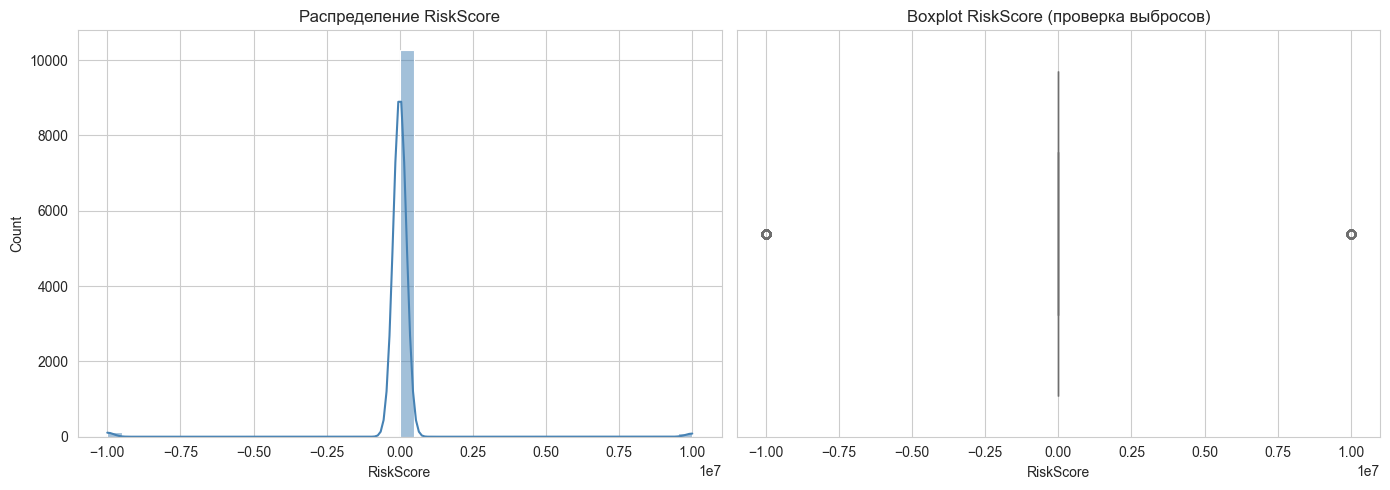

count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
max      1.000000e+07
Name: RiskScore, dtype: float64


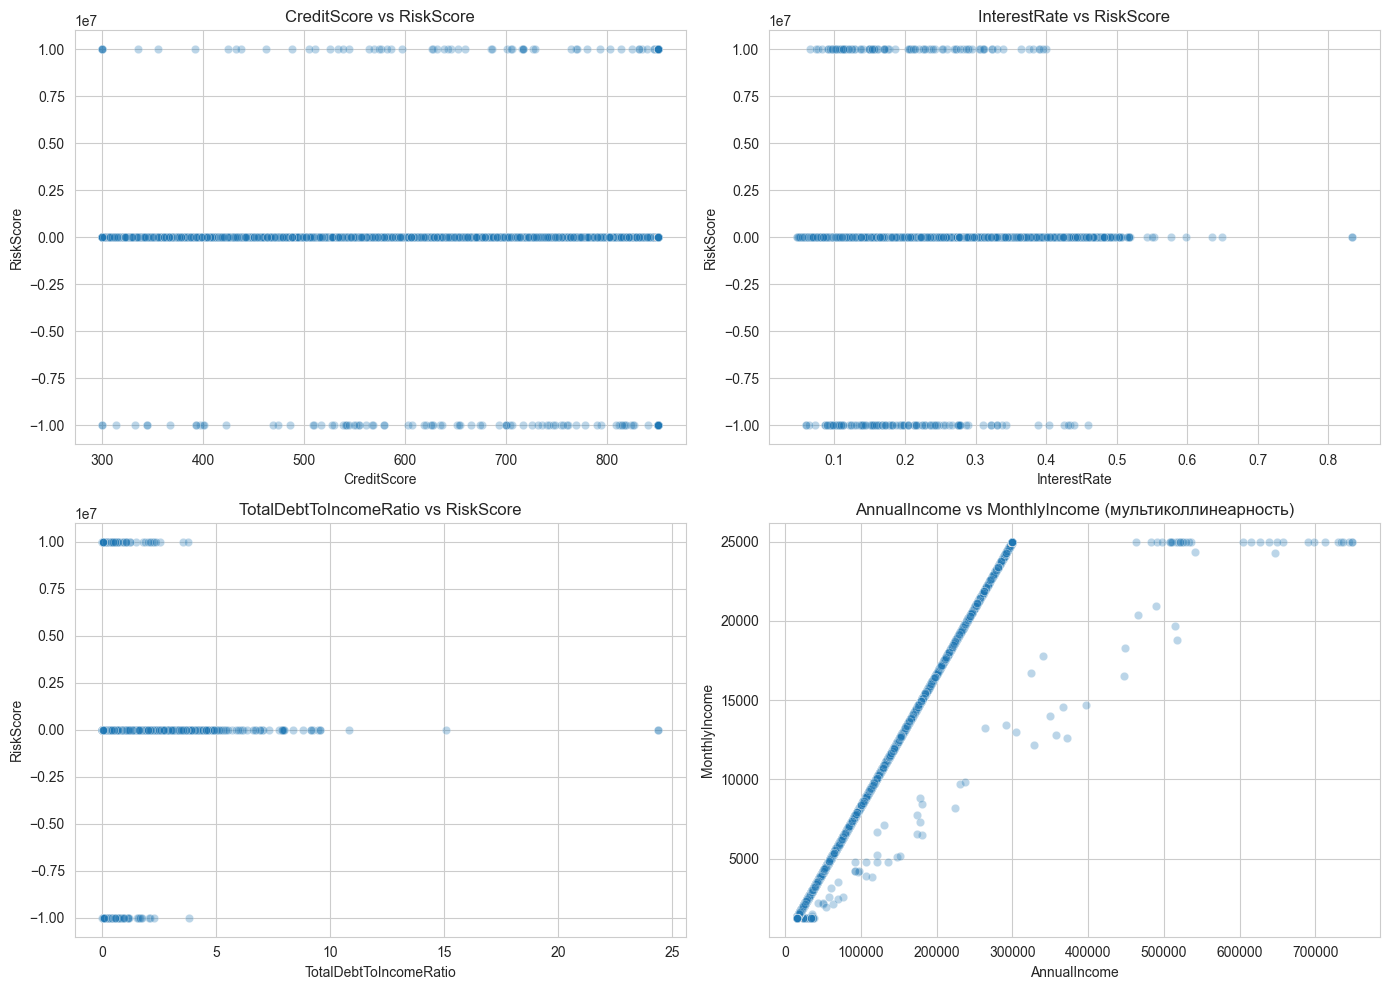

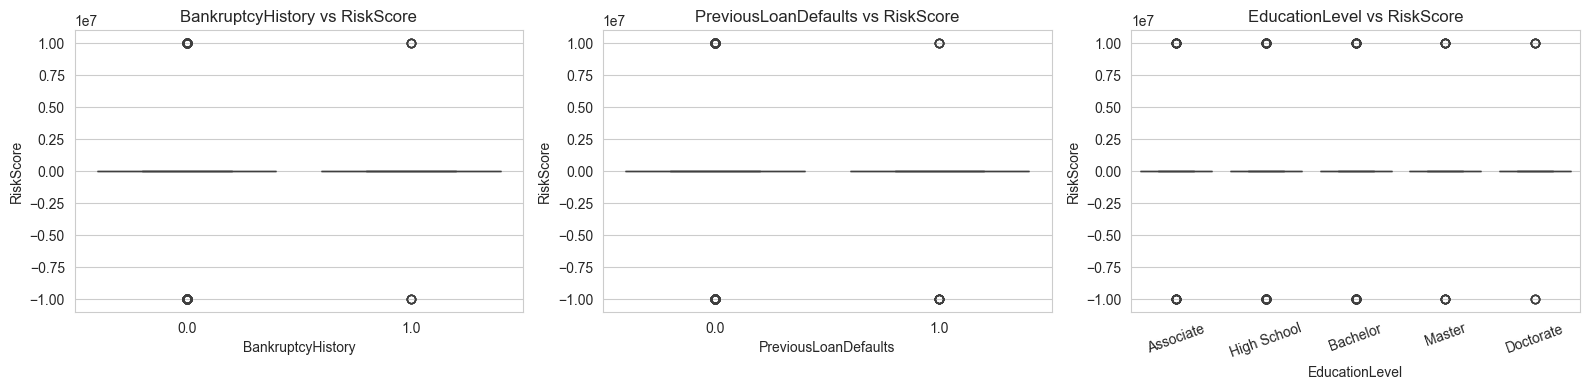

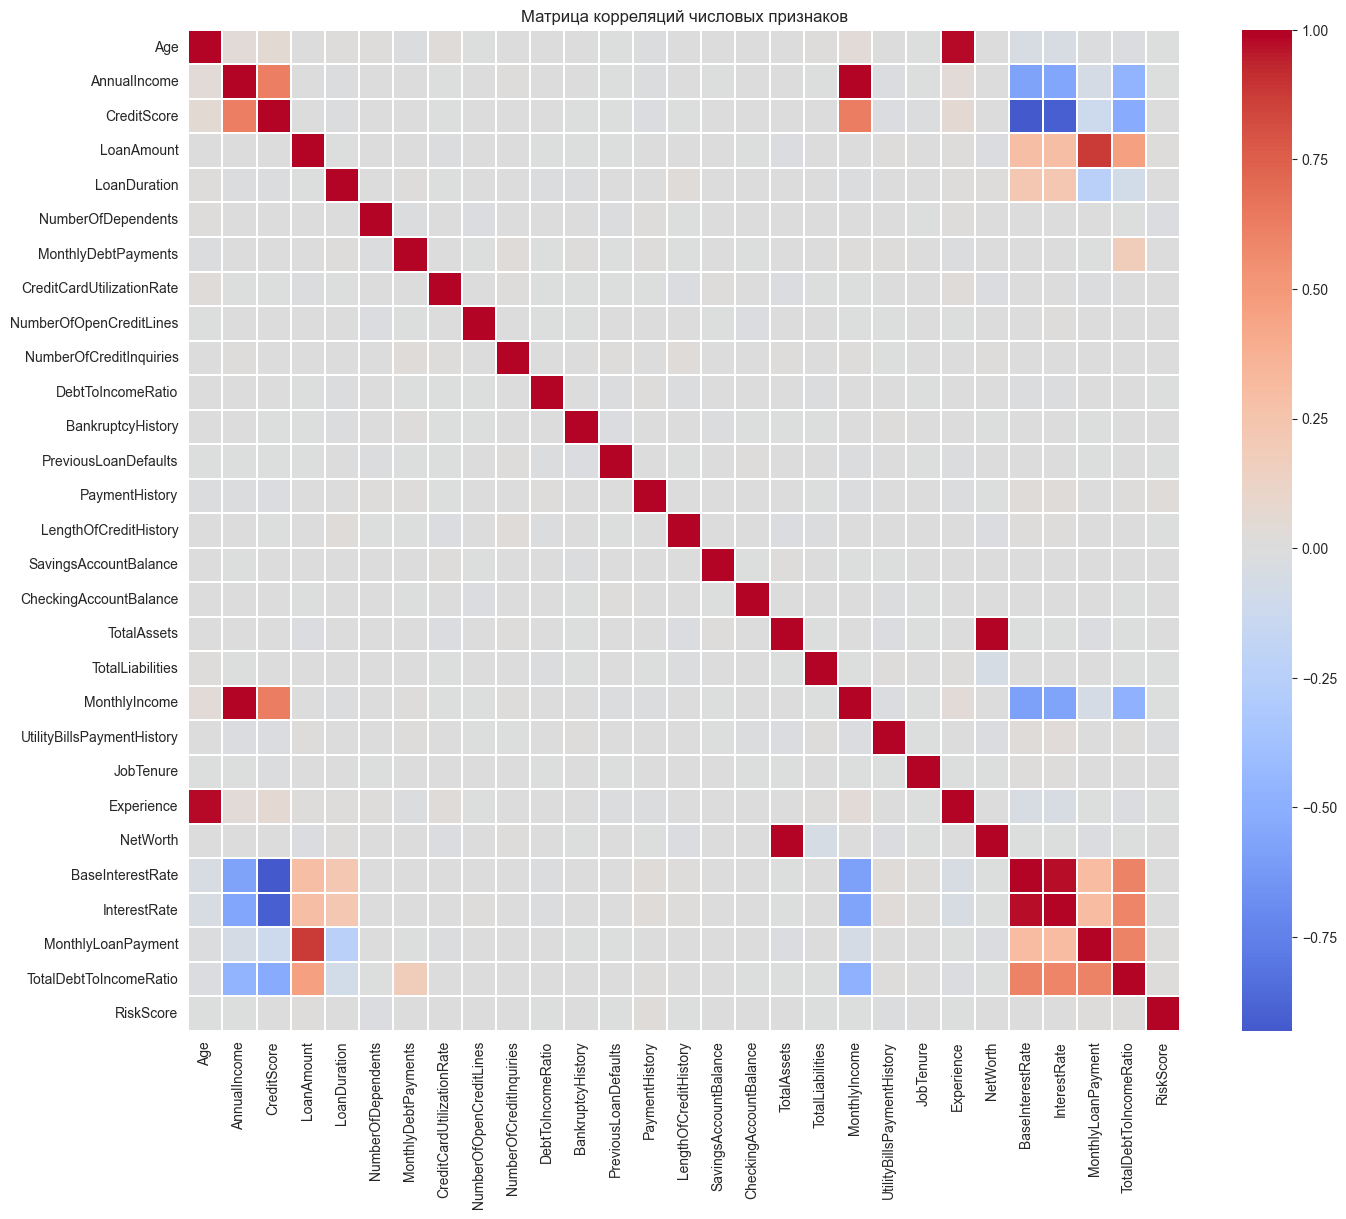

Топ корреляций с RiskScore:
RiskScore                     1.000000
PaymentHistory                0.019144
TotalDebtToIncomeRatio        0.013879
MonthlyLoanPayment            0.012366
LoanAmount                    0.011771
NumberOfCreditInquiries       0.011055
NetWorth                      0.008804
TotalAssets                   0.008092
SavingsAccountBalance         0.007611
CreditCardUtilizationRate     0.005501
BankruptcyHistory             0.005184
JobTenure                     0.003822
InterestRate                  0.003388
CreditScore                   0.002383
BaseInterestRate              0.002081
NumberOfOpenCreditLines       0.000730
CheckingAccountBalance       -0.000648
MonthlyDebtPayments          -0.001871
LoanDuration                 -0.001880
Age                          -0.004648
TotalLiabilities             -0.004976
Experience                   -0.005408
PreviousLoanDefaults         -0.005409
MonthlyIncome                -0.006145
DebtToIncomeRatio            -0.0074

In [14]:
# 1. Распределение целевой переменной RiskScore
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_df["RiskScore"], bins=40, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Распределение RiskScore")

sns.boxplot(x=train_df["RiskScore"], ax=axes[1], color="lightcoral")
axes[1].set_title("Boxplot RiskScore (проверка выбросов)")
plt.tight_layout()
plt.show()

print(train_df["RiskScore"].describe())

# 2. Зависимости признаков друг от друга и от таргета
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(data=train_df, x="CreditScore", y="RiskScore", alpha=0.3, ax=axes[0, 0])
axes[0, 0].set_title("CreditScore vs RiskScore")

sns.scatterplot(data=train_df, x="InterestRate", y="RiskScore", alpha=0.3, ax=axes[0, 1])
axes[0, 1].set_title("InterestRate vs RiskScore")

sns.scatterplot(data=train_df, x="TotalDebtToIncomeRatio", y="RiskScore", alpha=0.3, ax=axes[1, 0])
axes[1, 0].set_title("TotalDebtToIncomeRatio vs RiskScore")

sns.scatterplot(data=train_df, x="AnnualIncome", y="MonthlyIncome", alpha=0.3, ax=axes[1, 1])
axes[1, 1].set_title("AnnualIncome vs MonthlyIncome (мультиколлинеарность)")

plt.tight_layout()
plt.show()

# 3. Зависимость RiskScore от категориальных / бинарных признаков
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=train_df, x="BankruptcyHistory", y="RiskScore", ax=axes[0])
axes[0].set_title("BankruptcyHistory vs RiskScore")

sns.boxplot(data=train_df, x="PreviousLoanDefaults", y="RiskScore", ax=axes[1])
axes[1].set_title("PreviousLoanDefaults vs RiskScore")

sns.boxplot(data=train_df, x="EducationLevel", y="RiskScore", ax=axes[2])
axes[2].set_title("EducationLevel vs RiskScore")
axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

# 4. Матрица корреляций числовых признаков
num_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[num_cols].corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False, linewidths=0.3)
plt.title("Матрица корреляций числовых признаков")
plt.show()

print("Топ корреляций с RiskScore:")
print(corr_matrix["RiskScore"].sort_values(ascending=False))

In [15]:
class ZScoreNormalizer:
    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        # Защита от деления на ноль для константных признаков
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=np.float64)
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class MinMaxNormalizer:
    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.min_ = np.min(X, axis=0)
        self.max_ = np.max(X, axis=0)
        self.range_ = self.max_ - self.min_
        self.range_[self.range_ == 0] = 1.0
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=np.float64)
        return (X - self.min_) / self.range_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


# Проверка совпадения со sklearn
X_dummy = np.random.randn(100, 5) * 10 + 3
assert np.allclose(ZScoreNormalizer().fit_transform(X_dummy), StandardScaler().fit_transform(X_dummy))
assert np.allclose(MinMaxNormalizer().fit_transform(X_dummy), MinMaxScaler().fit_transform(X_dummy))
print("Z-score и Min-Max нормализаторы полностью совпадают со sklearn!")

Z-score и Min-Max нормализаторы полностью совпадают со sklearn!


In [16]:
def mse_custom(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return np.mean((y_true - y_pred) ** 2)


def mae_custom(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    return np.mean(np.abs(y_true - y_pred))


def r2_custom(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot if ss_tot != 0 else 0.0


def mape_custom(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    eps = np.finfo(np.float64).eps
    return np.mean(np.abs(y_true - y_pred) / np.maximum(np.abs(y_true), eps))


# Тестирование и сравнение со sklearn
y_t = np.array([30.5, 45.2, 60.0, 28.1, 52.7])
y_p = np.array([31.0, 44.0, 58.5, 29.0, 50.1])

print(f"MSE : custom={mse_custom(y_t, y_p):.8f}, sklearn={mean_squared_error(y_t, y_p):.8f}")
print(f"MAE : custom={mae_custom(y_t, y_p):.8f}, sklearn={mean_absolute_error(y_t, y_p):.8f}")
print(f"R2  : custom={r2_custom(y_t, y_p):.8f}, sklearn={r2_score(y_t, y_p):.8f}")
print(f"MAPE: custom={mape_custom(y_t, y_p):.8f}, sklearn={mean_absolute_percentage_error(y_t, y_p):.8f}")

MSE : custom=2.30200000, sklearn=2.30200000
MAE : custom=1.34000000, sklearn=1.34000000
R2  : custom=0.98496879, sklearn=0.98496879
MAPE: custom=0.02986129, sklearn=0.02986129


In [17]:
class KFoldCustom:
    def __init__(self, n_splits=5, shuffle=True, random_state=42):
        if n_splits < 2:
            raise ValueError("n_splits должен быть >= 2")
        self.n_splits = n_splits
        self.shuffle = shuffle
        self.random_state = random_state

    def split(self, X):
        n_samples = len(X)
        indices = np.arange(n_samples)
        if self.shuffle:
            rng = np.random.default_rng(self.random_state)
            rng.shuffle(indices)

        fold_sizes = np.full(self.n_splits, n_samples // self.n_splits, dtype=int)
        fold_sizes[: n_samples % self.n_splits] += 1

        current = 0
        for fold_size in fold_sizes:
            val_idx = indices[current : current + fold_size]
            train_idx = np.concatenate([indices[:current], indices[current + fold_size :]])
            yield train_idx, val_idx
            current += fold_size


class LeaveOneOutCustom:
    def split(self, X):
        n_samples = len(X)
        indices = np.arange(n_samples)
        for i in range(n_samples):
            val_idx = np.array([i])
            train_idx = np.delete(indices, i)
            yield train_idx, val_idx


# Проверка KFold и LOO со sklearn
X_test_cv = np.zeros((25, 2))
kf_c = list(KFoldCustom(n_splits=5, shuffle=False).split(X_test_cv))
kf_s = list(KFold(n_splits=5, shuffle=False).split(X_test_cv))
for (tr1, va1), (tr2, va2) in zip(kf_c, kf_s):
    assert np.array_equal(tr1, tr2) and np.array_equal(va1, va2)

loo_c = list(LeaveOneOutCustom().split(X_test_cv))
loo_s = list(LeaveOneOut().split(X_test_cv))
for (tr1, va1), (tr2, va2) in zip(loo_c, loo_s):
    assert np.array_equal(tr1, tr2) and np.array_equal(va1, va2)

print("KFoldCustom и LeaveOneOutCustom полностью совпадают со sklearn!")

KFoldCustom и LeaveOneOutCustom полностью совпадают со sklearn!


In [18]:
class LinearRegressionCustom:
    def __init__(
        self,
        method="analytic",       # 'analytic', 'gd', 'sgd'
        lr=0.05,
        n_iter=2000,
        batch_size=1,            # для классического SGD = 1; можно задать mini-batch (напр. 64) для ускорения
        lr_decay=0.0,            # затухание шага: lr / (1 + lr_decay * step)
        tol=1e-7,
        reg=None,                # None, 'l1', 'l2', 'l1_l2', 'lp'
        alpha=0.0,               # сила регуляризации
        l1_ratio=0.5,            # доля L1 для 'l1_l2'
        p=2.0,                   # степень p для 'lp'
        random_state=42,
    ):
        self.method = method
        self.lr = lr
        self.n_iter = n_iter
        self.batch_size = batch_size
        self.lr_decay = lr_decay
        self.tol = tol
        self.reg = reg
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.p = p
        self.random_state = random_state
        self.coef_ = None
        self.intercept_ = None
        self.loss_history_ = []

    def _reg_penalty(self, w):
        if self.reg is None or self.alpha == 0:
            return 0.0
        if self.reg == "l1":
            return self.alpha * np.sum(np.abs(w))
        if self.reg == "l2":
            return self.alpha * np.sum(w ** 2)
        if self.reg == "l1_l2":
            return self.alpha * (
                self.l1_ratio * np.sum(np.abs(w)) + (1.0 - self.l1_ratio) * np.sum(w ** 2)
            )
        if self.reg == "lp":
            if self.p <= 0:
                raise ValueError("Для Lp-регуляризации p должно быть > 0")
            return self.alpha * np.sum(np.abs(w) ** self.p)
        raise ValueError(f"Неизвестный тип регуляризации: {self.reg}")

    def _reg_grad(self, w):
        if self.reg is None or self.alpha == 0:
            return np.zeros_like(w)
        if self.reg == "l1":
            return self.alpha * np.sign(w)
        if self.reg == "l2":
            return 2.0 * self.alpha * w
        if self.reg == "l1_l2":
            return self.alpha * (
                self.l1_ratio * np.sign(w) + 2.0 * (1.0 - self.l1_ratio) * w
            )
        if self.reg == "lp":
            if self.p <= 0:
                raise ValueError("Для Lp-регуляризации p должно быть > 0")
            grad = np.zeros_like(w)
            nonzero = np.abs(w) > 1e-12
            grad[nonzero] = (
                self.alpha * self.p * (np.abs(w[nonzero]) ** (self.p - 1.0)) * np.sign(w[nonzero])
            )
            return grad
        raise ValueError(f"Неизвестный тип регуляризации: {self.reg}")

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64).ravel()
        n_samples, n_features = X.shape
        self.loss_history_ = []

        if self.method == "analytic":
            if self.reg not in (None, "l2"):
                raise ValueError(
                    "Аналитическая формула поддерживается только без регуляризации или для L2. "
                    "Для L1, L1+L2 и Lp используйте method='gd' или 'sgd'."
                )
            X_b = np.column_stack([np.ones(n_samples), X])
            gram = X_b.T @ X_b
            if self.reg == "l2" and self.alpha > 0:
                reg_mat = np.eye(n_features + 1) * (n_samples * self.alpha)
                reg_mat[0, 0] = 0.0  # не штрафуем intercept
                gram = gram + reg_mat
            theta = np.linalg.pinv(gram) @ (X_b.T @ y)
            self.intercept_ = float(theta[0])
            self.coef_ = theta[1:]
            return self

        w = np.zeros(n_features, dtype=np.float64)
        b = 0.0
        rng = np.random.default_rng(self.random_state)

        if self.method == "gd":
            prev_loss = np.inf
            for it in range(self.n_iter):
                y_pred = X @ w + b
                error = y_pred - y
                loss = np.mean(error ** 2) + self._reg_penalty(w)
                self.loss_history_.append(loss)

                if abs(prev_loss - loss) < self.tol:
                    break
                prev_loss = loss

                grad_w = (2.0 / n_samples) * (X.T @ error) + self._reg_grad(w)
                grad_b = (2.0 / n_samples) * np.sum(error)

                step_lr = self.lr / (1.0 + self.lr_decay * it)
                w -= step_lr * grad_w
                b -= step_lr * grad_b

        elif self.method == "sgd":
            step = 0
            for epoch in range(self.n_iter):
                indices = rng.permutation(n_samples)
                for start in range(0, n_samples, self.batch_size):
                    batch_idx = indices[start : start + self.batch_size]
                    X_b = X[batch_idx]
                    y_b = y[batch_idx]
                    m = len(batch_idx)

                    error = (X_b @ w + b) - y_b
                    grad_w = (2.0 / m) * (X_b.T @ error) + self._reg_grad(w)
                    grad_b = (2.0 / m) * np.sum(error)

                    # Защита от расходимости шага
                    grad_w = np.clip(grad_w, -1e6, 1e6)
                    grad_b = np.clip(grad_b, -1e6, 1e6)

                    step_lr = self.lr / (1.0 + self.lr_decay * step)
                    w -= step_lr * grad_w
                    b -= step_lr * grad_b
                    step += 1

                epoch_loss = np.mean((X @ w + b - y) ** 2) + self._reg_penalty(w)
                self.loss_history_.append(epoch_loss)
                if epoch > 0 and abs(self.loss_history_[-2] - epoch_loss) < self.tol:
                    break
        else:
            raise ValueError(f"Неизвестный метод обучения: {self.method}")

        self.coef_ = w
        self.intercept_ = float(b)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return X @ self.coef_ + self.intercept_

In [19]:
# Синтетический тест (чтобы проверить сходимость всех методов на одном масштабе)
rng = np.random.default_rng(42)
X_syn = ZScoreNormalizer().fit_transform(rng.normal(size=(500, 8)))
true_w = np.array([5.0, -3.2, 0.0, 2.5, 0.0, -1.8, 4.1, 0.0])
y_syn = X_syn @ true_w + 10.0 + rng.normal(scale=0.5, size=500)

models = {
    "Custom Analytic": LinearRegressionCustom(method="analytic").fit(X_syn, y_syn),
    "Custom GD": LinearRegressionCustom(method="gd", lr=0.1, n_iter=2000).fit(X_syn, y_syn),
    "Custom SGD": LinearRegressionCustom(method="sgd", lr=0.02, lr_decay=1e-4, n_iter=100, batch_size=1).fit(X_syn, y_syn),
    "Sklearn LinearRegression": LinearRegression().fit(X_syn, y_syn),
    "Sklearn SGDRegressor": SGDRegressor(max_iter=1000, tol=1e-6, random_state=42).fit(X_syn, y_syn),
}

for name, m in models.items():
    preds = m.predict(X_syn)
    print(f"{name:25s} | MSE={mse_custom(y_syn, preds):.6f} | R2={r2_custom(y_syn, preds):.6f}")

# Проверка регуляризаций (L1, L2, L1+L2, Lp)
reg_models = {
    "Custom L1 (GD)": LinearRegressionCustom(method="gd", lr=0.1, n_iter=3000, reg="l1", alpha=0.5).fit(X_syn, y_syn),
    "Sklearn Lasso": Lasso(alpha=0.25, max_iter=5000).fit(X_syn, y_syn),
    "Custom L2 (Analytic)": LinearRegressionCustom(method="analytic", reg="l2", alpha=0.1).fit(X_syn, y_syn),
    "Sklearn Ridge": Ridge(alpha=50.0).fit(X_syn, y_syn),  # alpha_sklearn = n * alpha_custom = 500 * 0.1
    "Custom L1+L2 (GD)": LinearRegressionCustom(method="gd", lr=0.1, n_iter=3000, reg="l1_l2", alpha=0.5, l1_ratio=0.5).fit(X_syn, y_syn),
    "Sklearn ElasticNet": ElasticNet(alpha=0.25, l1_ratio=0.5, max_iter=5000).fit(X_syn, y_syn),
    "Custom Lp (p=1.5)": LinearRegressionCustom(method="gd", lr=0.05, n_iter=3000, reg="lp", alpha=0.2, p=1.5).fit(X_syn, y_syn),
    "Custom Lp (p=3.0)": LinearRegressionCustom(method="gd", lr=0.01, n_iter=3000, reg="lp", alpha=0.05, p=3.0).fit(X_syn, y_syn),
}

print("\n--- Сравнение регуляризаций ---")
for name, m in reg_models.items():
    preds = m.predict(X_syn)
    n_zero = np.sum(np.abs(m.coef_) < 1e-2)
    print(f"{name:22s} | MSE={mse_custom(y_syn, preds):.4f} | ||w||_2={np.linalg.norm(m.coef_):.3f} | ~zero coefs={n_zero}")

Custom Analytic           | MSE=0.237557 | R2=0.995947
Custom GD                 | MSE=0.237557 | R2=0.995947
Custom SGD                | MSE=0.239629 | R2=0.995912
Sklearn LinearRegression  | MSE=0.237557 | R2=0.995947
Sklearn SGDRegressor      | MSE=0.237583 | R2=0.995947

--- Сравнение регуляризаций ---
Custom L1 (GD)         | MSE=0.5705 | ||w||_2=7.309 | ~zero coefs=1
Sklearn Lasso          | MSE=0.5687 | ||w||_2=7.310 | ~zero coefs=3
Custom L2 (Analytic)   | MSE=0.7772 | ||w||_2=7.106 | ~zero coefs=1
Sklearn Ridge          | MSE=0.7772 | ||w||_2=7.106 | ~zero coefs=1
Custom L1+L2 (GD)      | MSE=3.5404 | ||w||_2=5.993 | ~zero coefs=2
Sklearn ElasticNet     | MSE=1.5328 | ||w||_2=6.698 | ~zero coefs=3
Custom Lp (p=1.5)      | MSE=0.6030 | ||w||_2=7.249 | ~zero coefs=1
Custom Lp (p=3.0)      | MSE=2.6724 | ||w||_2=6.284 | ~zero coefs=0


In [20]:
EDU_ORDER = {
    "High School": 0,
    "Associate": 1,
    "Bachelor": 2,
    "Master": 3,
    "Doctorate": 4,
    "PhD": 4,
}

CAT_COLS = ["MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "EmploymentStatus"]

def preprocess_features(train_raw, test_raw):
    # 1. Удаляем строки train, где отсутствует или некорректен таргет RiskScore
    tr = train_raw[np.isfinite(train_raw["RiskScore"])].copy().reset_index(drop=True)
    te = test_raw.copy().reset_index(drop=True)

    y_train = tr["RiskScore"].values.astype(np.float64)
    test_ids = te["ID"].values
    tr = tr.drop(columns=["RiskScore"])
    te = te.drop(columns=["ID"])

    # 2. Обработка даты и EducationLevel
    for df in (tr, te):
        dt = pd.to_datetime(df["ApplicationDate"], errors="coerce")
        df["AppYear"] = dt.dt.year
        df["AppMonth"] = dt.dt.month
        df.drop(columns=["ApplicationDate"], inplace=True)

        # Аккуратное кодирование EducationLevel
        df["EducationLevel"] = (
            df["EducationLevel"]
            .astype(str)
            .str.strip()
            .map(EDU_ORDER)
        )

        # Удаляем 100% коллинеарный MonthlyIncome
        if "MonthlyIncome" in df.columns:
            df.drop(columns=["MonthlyIncome"], inplace=True)

    # 3. Заполнение пропусков в исходных признаках статистиками train
    num_cols = [c for c in tr.columns if c not in CAT_COLS]
    for col in num_cols:
        tr[col] = pd.to_numeric(tr[col], errors="coerce")
        te[col] = pd.to_numeric(te[col], errors="coerce")
        med = tr[col].median()
        if pd.isna(med):
            med = 0.0
        tr[col] = tr[col].fillna(med)
        te[col] = te[col].fillna(med)

    for col in CAT_COLS:
        tr[col] = tr[col].fillna("Missing").astype(str)
        te[col] = te[col].fillna("Missing").astype(str)

    # 4. Инженерные признаки (безопасные знаменатели через np.maximum(..., 0))
    skewed_pos = [
        "AnnualIncome", "LoanAmount", "MonthlyDebtPayments",
        "SavingsAccountBalance", "CheckingAccountBalance",
        "TotalAssets", "TotalLiabilities", "MonthlyLoanPayment",
    ]
    for df in (tr, te):
        df["LoanToIncome"] = df["LoanAmount"] / (np.maximum(df["AnnualIncome"], 0.0) + 1.0)
        df["InterestSpread"] = df["InterestRate"] - df["BaseInterestRate"]
        df["AssetsToLiabilities"] = df["TotalAssets"] / (np.maximum(df["TotalLiabilities"], 0.0) + 1.0)
        df["LiquidAssets"] = df["SavingsAccountBalance"] + df["CheckingAccountBalance"]
        df["LiquidToLoan"] = df["LiquidAssets"] / (np.maximum(df["LoanAmount"], 0.0) + 1.0)
        df["CreditScoreInv"] = 850.0 - df["CreditScore"]

        for col in skewed_pos:
            df[f"log_{col}"] = np.log1p(np.maximum(df[col], 0.0))

        df["slog_NetWorth"] = np.sign(df["NetWorth"]) * np.log1p(np.abs(df["NetWorth"]))

    # 5. One-Hot Encoding с выравниванием столбцов train и test
    full = pd.concat([tr, te], axis=0, ignore_index=True)
    full = pd.get_dummies(full, columns=CAT_COLS, drop_first=True, dtype=np.float64)

    # 6. Финальная зачистка любых возможных inf / NaN
    full.replace([np.inf, -np.inf], np.nan, inplace=True)
    X_tr_df = full.iloc[: len(tr)].reset_index(drop=True)
    X_te_df = full.iloc[len(tr) :].reset_index(drop=True)

    train_medians = X_tr_df.median().fillna(0.0)
    X_tr_df = X_tr_df.fillna(train_medians)
    X_te_df = X_te_df.fillna(train_medians)

    assert np.isfinite(X_tr_df.values).all(), "В X_tr_df остались NaN/Inf!"
    assert np.isfinite(X_te_df.values).all(), "В X_te_df остались NaN/Inf!"
    assert np.isfinite(y_train).all(), "В y_train остались NaN/Inf!"

    return X_tr_df, y_train, X_te_df, test_ids


X_tr_df, y_train, X_te_df, test_ids = preprocess_features(train_df, test_df)
print("OK! Форма X_tr_df:", X_tr_df.shape, "| Форма y_train:", y_train.shape)

OK! Форма X_tr_df: (10487, 58) | Форма y_train: (10487,)


In [21]:
def evaluate_kfold(X, y, model_factory, use_poly=False, degree=2, n_splits=5):
    kf = KFoldCustom(n_splits=n_splits, shuffle=True, random_state=42)
    mses, maes, r2s, mapes = [], [], [], []
    oof_preds = np.zeros_like(y)

    for train_idx, val_idx in kf.split(X):
        X_tr, X_va = X[train_idx], X[val_idx]
        y_tr, y_va = y[train_idx], y[val_idx]

        if use_poly:
            poly = PolynomialFeatures(degree=degree, include_bias=False)
            X_tr = poly.fit_transform(X_tr)
            X_va = poly.transform(X_va)

        scaler = ZScoreNormalizer()
        X_tr_s = scaler.fit_transform(X_tr)
        X_va_s = scaler.transform(X_va)

        model = model_factory()
        model.fit(X_tr_s, y_tr)
        preds = model.predict(X_va_s)
        oof_preds[val_idx] = preds

        mses.append(mse_custom(y_va, preds))
        maes.append(mae_custom(y_va, preds))
        r2s.append(r2_custom(y_va, preds))
        mapes.append(mape_custom(y_va, preds))

    return {
        "MSE": np.mean(mses),
        "MAE": np.mean(maes),
        "R2": np.mean(r2s),
        "MAPE": np.mean(mapes),
        "oof": oof_preds,
    }


X_raw_np = X_tr_df.values

# 1. Базовая линейная регрессия (без полиномов)
res_base = evaluate_kfold(
    X_raw_np, y_train,
    lambda: LinearRegressionCustom(method="analytic", reg="l2", alpha=1e-4),
    use_poly=False,
)
print("Базовая модель (без полиномов):", {k: round(v, 4) for k, v in res_base.items() if k != "oof"})

# 2. Подбор alpha с полиномиальными признаками 2-й степени
best_alpha, best_mse = None, np.inf
for alpha in [1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1]:
    res = evaluate_kfold(
        X_raw_np, y_train,
        lambda a=alpha: LinearRegressionCustom(method="analytic", reg="l2", alpha=a),
        use_poly=True, degree=2,
    )
    print(f"Poly(deg=2) + L2 alpha={alpha:<7} -> MSE={res['MSE']:.4f}, MAE={res['MAE']:.4f}, R2={res['R2']:.4f}, MAPE={res['MAPE']:.4f}")
    if res["MSE"] < best_mse:
        best_mse = res["MSE"]
        best_alpha = alpha

print(f"\nЛучший alpha={best_alpha}, CV MSE={best_mse:.4f}")

Базовая модель (без полиномов): {'MSE': np.float64(2062938143005.6567), 'MAE': np.float64(291845.6265), 'R2': np.float64(-0.0075), 'MAPE': np.float64(2056.629)}
Poly(deg=2) + L2 alpha=0.0001  -> MSE=3266174647353.0205, MAE=703462.1493, R2=-0.5590, MAPE=11818.6754
Poly(deg=2) + L2 alpha=0.0005  -> MSE=2895862292190.8398, MAE=660915.1361, R2=-0.3946, MAPE=10799.4876
Poly(deg=2) + L2 alpha=0.001   -> MSE=2691701204926.1641, MAE=638346.4797, R2=-0.3060, MAPE=10259.4124
Poly(deg=2) + L2 alpha=0.005   -> MSE=2376511795522.5732, MAE=581351.6497, R2=-0.1649, MAPE=8898.0865
Poly(deg=2) + L2 alpha=0.01    -> MSE=2305201391108.7275, MAE=555515.3371, R2=-0.1309, MAPE=8280.7342
Poly(deg=2) + L2 alpha=0.05    -> MSE=2205797369524.6831, MAE=486611.1871, R2=-0.0805, MAPE=6645.6428
Poly(deg=2) + L2 alpha=0.1     -> MSE=2168545382820.7798, MAE=449514.9601, R2=-0.0613, MAPE=5770.1094

Лучший alpha=0.1, CV MSE=2168545382820.7798


In [22]:
print("NaN в RiskScore:", train_df["RiskScore"].isna().sum())
print("Inf в RiskScore:", np.isinf(train_df["RiskScore"]).sum())
print("Уникальные EducationLevel:", train_df["EducationLevel"].unique())

nan_cols = X_tr_df.columns[X_tr_df.isna().any()].tolist()
inf_cols = X_tr_df.columns[np.isinf(X_tr_df).any()].tolist()
print("Столбцы X_tr_df с NaN:", nan_cols)
print("Столбцы X_tr_df с Inf:", inf_cols)

NaN в RiskScore: 530
Inf в RiskScore: 0
Уникальные EducationLevel: ['Associate' 'High School' 'Bachelor' 'Master' 'Doctorate' nan]
Столбцы X_tr_df с NaN: []
Столбцы X_tr_df с Inf: []


In [23]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_tr_df.values)
X_test_poly = poly.transform(X_te_df.values)

scaler = ZScoreNormalizer()
X_train_scaled = scaler.fit_transform(X_train_poly)
X_test_scaled = scaler.transform(X_test_poly)

final_model = LinearRegressionCustom(method="analytic", reg="l2", alpha=best_alpha)
final_model.fit(X_train_scaled, y_train)

test_preds = final_model.predict(X_test_scaled)

# Если RiskScore по смыслу строго в [0, 100] (проверьте min/max на train!), можно проверить клиппинг:
# test_preds = np.clip(test_preds, y_train.min(), y_train.max())

submission = pd.DataFrame({
    "ID": test_ids,
    "RiskScore": test_preds,
})
submission.to_csv("submission.csv", index=False)
print("Сохранено в submission.csv. Первые 5 строк:")
print(submission.head())

Сохранено в submission.csv. Первые 5 строк:
   ID      RiskScore
0   0   95949.518224
1   1  171760.715197
2   2  246672.467412
3   3 -230705.443419
4   4  -39070.960692


In [24]:
rs = train_df["RiskScore"].dropna()
print("Квантили RiskScore:")
print(rs.quantile([0.0, 0.005, 0.01, 0.05, 0.5, 0.95, 0.99, 0.995, 1.0]))

print("\nКоличество строк с RiskScore < 0:", (rs < 0).sum())
print("Количество строк с RiskScore > 100:", (rs > 100).sum())
print("Примеры аномальных RiskScore (<0 или >100):")
print(rs[(rs < 0) | (rs > 100)].head(15).values)

# Также проверим min/max числовых признаков в train и test
num_cols = train_df.select_dtypes(include=[np.number]).columns.drop("RiskScore")
summary = pd.DataFrame({
    "train_min": train_df[num_cols].min(),
    "train_p01": train_df[num_cols].quantile(0.01),
    "train_p99": train_df[num_cols].quantile(0.99),
    "train_max": train_df[num_cols].max(),
    "test_min": test_df[num_cols].min(),
    "test_max": test_df[num_cols].max(),
})
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 140)
print("\nСводка признаков (поиск выбросов в train и test):")
print(summary)

Квантили RiskScore:
0.000   -9.999999e+06
0.005   -9.999999e+06
0.010   -9.999999e+06
0.050    2.598087e+01
0.500    4.411876e+01
0.950    7.646136e+01
0.990    9.022040e+01
0.995    1.000000e+07
1.000    1.000000e+07
Name: RiskScore, dtype: float64

Количество строк с RiskScore < 0: 121
Количество строк с RiskScore > 100: 94
Примеры аномальных RiskScore (<0 или >100):
[-9999999. -9999999. -9999999. -9999999. -9999999. 10000000. -9999999.
 10000000. -9999999. -9999999. 10000000. -9999999. -9999999. -9999999.
 -9999999.]

Сводка признаков (поиск выбросов в train и test):
                               train_min     train_p01     train_p99     train_max      test_min      test_max
Age                            18.000000     18.000000  6.700000e+01  8.000000e+01     18.000000  8.000000e+01
AnnualIncome                15000.000000  15000.000000  3.000000e+05  7.485080e+05  15000.000000  7.492830e+05
CreditScore                   300.000000    300.000000  8.500000e+02  8.500000e+02    300.